# Pós-processamento — Análise das descrições SLM

Percorre `outputs/slm_descriptions/coco_descriptions.jsonl` e mede, por descrição gerada:

- **Tamanho do texto** (nº de caracteres)
- **Quantidade de palavras**
- **Quantidade de períodos textuais** (sentenças)
- **Quantidade de adjetivos** (POS tagging via NLTK — tags `JJ`, `JJR`, `JJS`)

Ao final, agrega as estatísticas (média, mediana, desvio) sobre todo o corpus.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

JSONL_PATH = Path("../../outputs/slm_descriptions/coco_descriptions.jsonl")

records = []
with JSONL_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        obj = json.loads(line)
        records.append(obj.get("description", "") or "")

print(f"Total de descrições: {len(records):,}")

Total de descrições: 163,957


In [7]:
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk import pos_tag
import matplotlib.pyplot as plt

ADJ_TAGS = {"JJ", "JJR", "JJS"}


def analyze(text):
    n_chars = len(text)
    sentences = sent_tokenize(text)
    n_sentences = len(sentences)
    tokens = word_tokenize(text)
    words = [t for t in tokens if any(c.isalpha() for c in t)]
    n_words = len(words)
    tagged = pos_tag(tokens)
    n_adjectives = sum(1 for _, tag in tagged if tag in ADJ_TAGS)
    return n_chars, n_words, n_sentences, n_adjectives

In [4]:
from multiprocessing import Pool, cpu_count

n_workers = max(1, cpu_count() - 1)
with Pool(n_workers) as pool:
    results = pool.map(analyze, records, chunksize=500)

df = pd.DataFrame(
    results,
    columns=["n_chars", "n_words", "n_sentences", "n_adjectives"],
)
df.head()

,n_chars,n_words,n_sentences,n_adjectives
0,1300,218,11,37
1,1275,211,10,21
2,1138,189,8,25
3,1176,196,9,24
4,1248,210,11,28


In [5]:
summary = df.agg(["mean", "median", "std", "min", "max"]).T
summary.columns = ["média", "mediana", "desvio_padrão", "mínimo", "máximo"]
summary.index = [
    "caracteres",
    "palavras",
    "períodos (sentenças)",
    "adjetivos",
]
summary.round(2)

,média,mediana,desvio_padrão,mínimo,máximo
caracteres,1255.51,1264.0,67.21,636.0,1481.0
palavras,212.55,215.0,10.64,73.0,234.0
períodos (sentenças),10.03,10.0,1.08,3.0,16.0
adjetivos,25.52,25.0,4.75,6.0,49.0


In [6]:
print(f"Descrições analisadas: {len(df):,}\n")
print(f"Tamanho médio do texto : {df['n_chars'].mean():.1f} caracteres")
print(f"Palavras (média)       : {df['n_words'].mean():.1f}")
print(f"Períodos (média)       : {df['n_sentences'].mean():.2f}")
print(f"Adjetivos (média)      : {df['n_adjectives'].mean():.2f}")
print(f"Densidade de adjetivos : {100 * df['n_adjectives'].sum() / df['n_words'].sum():.1f}% das palavras")

Descrições analisadas: 163,957

Tamanho médio do texto : 1255.5 caracteres
Palavras (média)       : 212.5
Períodos (média)       : 10.03
Adjetivos (média)      : 25.52
Densidade de adjetivos : 12.0% das palavras


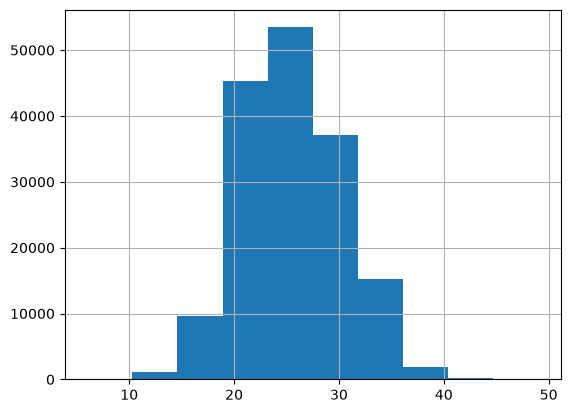

In [8]:
df['n_adjectives'].hist()
plt.show()

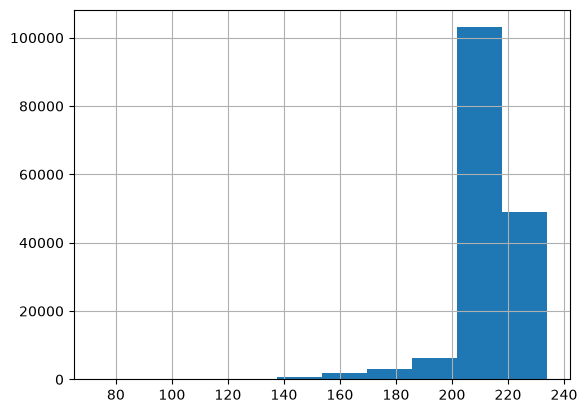

In [11]:
df['n_words'].hist()
plt.show()